In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Trapezoidal Rule


$$I = h/2[(Y0-Yn-1) + 2 (Y1+Y2+...+Yn-1)]$$
![Description](https://media.geeksforgeeks.org/wp-content/uploads/20241231110823198597/trapezoid_rule.webp)

In [88]:
def trapz(y,x):
    # determine spacing array
    h=float(x[1]-x[0])
    
    
    
    # sum of h x non-end points
    I=sum(h*y[1:-1])
    
    # add one-half h x end points
    I+=(y[0]+y[-1])*h/2
    
    return I

t=np.arange(0,121,10)
v=np.array([-12.8, 62.6 , 131.55, 206.65, 262.9 , 312.  , 362.5 , 412.75, 511.4 , 577.  , 635.05, 665.7, 617.7])

trapz(v,t)



44425.5

### Selected Functions For The Assignment
1- $$f(x) = x^2; x = \{0,1,2,...,10\}$$
2- $$f(x) = x^5; x = \{0,1,2,...,10\}$$

### Determining Area under the curve using Trapezoidal Rule for the Following Functions.


#### FUNCTION 1: $$f(x) = x^2; x = \{0,1,2,...,10\}$$

-- The Exact Analytical Integral is: <b>1000/3 = 333.33333</b> <br>



In [43]:
# 1. Define the mathematical function cleanly
def f(x):
    """Returns the value of f(x) = x^2."""
    return x ** 2

def exact_analytical_integral_f1(start, end):
    return ((end**3)/3 - (start**3)/3)
    

# 2. Use a loop to calculate or sum values over a range
start = 0
end = 10
step = 1

X = np.array([x for x in range(start, end, step)])
Y = np.array([f(x) for x in range(start, end, step)])

# Trapezoid of the Function 
trap = trapz(Y,X)
exact_int = exact_analytical_integral_f1(start, end)

print("TRAPEZOIDE OF THE FUNCTION:\t", trap)
print("EXACT ANAYTICAL INTEGRAL:\t", exact_int)
print("ERROR:\t", abs(exact_int - trap))


TRAPEZOIDE OF THE FUNCTION:	 244.5
EXACT ANAYTICAL INTEGRAL:	 333.3333333333333
ERROR:	 88.83333333333331


#### FUNCTION 2: $$f(x) = x^5; x = \{0,1,2,...,10\}$$

-- The Exact Analytical Integral is: <b>1000000/6 = 166,666.6666666</b> <br>



In [141]:
def f2(x):
    """Returns the value of f(x) = x^2."""
    return x ** 5

def exact_analytical_integral_f2(start, end):
    return ((end**6)/6 - (start**6)/6)
    
    
Y = np.array([f2(x) for x in range(start, end, step)])

# Trapezoid of the Function 
trap = trapz(Y,X)
exact_int = exact_analytical_integral_f2(start, end)

print("TRAPEZOIDE OF THE FUNCTION:\t", trap)
print("EXACT ANAYTICAL INTEGRAL:\t", exact_int)
print("ERROR:\t", abs(exact_int - trap))


TRAPEZOIDE OF THE FUNCTION:	 6672.8515625
EXACT ANAYTICAL INTEGRAL:	 295260.1666666667
ERROR:	 288587.3151041667


# Simpson's Rule

$$\int _{a}^{b}f(x)\,dx\approx \frac{h}{3}\left[f(x_{0})+4f(x_{1})+2f(x_{2})+4f(x_{3})+\dots +2f(x_{n-2})+4f(x_{n-1})+f(x_{n})\right]$$


![Description](https://ars.els-cdn.com/content/image/3-s2.0-B9780128122563000130-gr002.gif)

### Determining Area under the curve using Simpson's Rule for the Selected Functions.


#### FUNCTION 1: $$f(x) = x^2; x = \{0,1,2,...,10\}$$

In [90]:
def simps(y,x):
    
    if len(y) % 2 == 0:
        print("provide odd number of data points")
        return
    
    # determine spacing array
    h=x[1]-x[0]
    
    # end points
    I=(y[0]+y[-1])*h/3
    
    # even points, start at 2, move in steps of 2 until n-3
    I+=sum(y[2:-1:2])*2*h/3
    
    # odd points, start at 1, move in steps of 2 until n-2
    I+=sum(y[1:-1:2])*4*h/3
    
    return I




start = 0
end = 11
step = 1

X = np.array([x for x in range(start, end, step)])
Y = np.array([f(x) for x in range(start, end, step)])

# Trapezoid of the Function 
sim_valu = simps(Y,X)
exact_int = exact_analytical_integral_f1(start, end)

print("Simpson's Result OF THE FUNCTION:\t", sim_valu)
print("EXACT ANAYTICAL INTEGRAL:\t", exact_int)
print("ERROR:\t", abs(exact_int - sim_valu))


Simpson's Result OF THE FUNCTION:	 333.33333333333337
EXACT ANAYTICAL INTEGRAL:	 443.6666666666667
ERROR:	 110.33333333333331


#### FUNCTION 2: $$f(x) = x^5; x = \{0,1,2,...,10\}$$

In [54]:
start = 0
end = 11
step = 1

X = np.array([x for x in range(start, end, step)])
Y = np.array([f2(x) for x in range(start, end, step)])

# Trapezoid of the Function 
sim_value = simps(Y,X)
exact_int = exact_analytical_integral_f2(start, end)

print("Simpson's Result OF THE FUNCTION:\t", sim_value)
print("EXACT ANAYTICAL INTEGRAL:\t", exact_int)
print("ERROR:\t", abs(exact_int - sim_value))

Simpson's Result OF THE FUNCTION:	 166700.0
EXACT ANAYTICAL INTEGRAL:	 295260.1666666667
ERROR:	 128560.16666666669


# Comparison of Both Methods

In [120]:
# Define the inputs/integration points
a = 0
b = 5
step = 1


f1_exact_integral = exact_analytical_integral_f1(a, b)
f2_exact_integral = exact_analytical_integral_f2(a, b)

f1_sim_errors = []
f1_trap_errors = []

f2_sim_errors = []
f2_trap_errors = []

interval_counts = [4, 8, 16, 32, 64, 128]


for n in interval_counts:
    
    X = np.linspace(a, b, n + 1)
    
    
    f1_values = np.array([f(x) for x in X])
    f2_values = np.array([f2(x) for x in X])
    
    f1_sim_value = simps(f1_values, X)
    f1_trap_value = trapz(f1_values, X)
    
    f2_sim_value = simps(f2_values, X)
    f2_trap_value = trapz(f2_values, X)


    
    f1_sim_errors.append(abs(f1_sim_value-f1_exact_integral))
    f1_trap_errors.append(abs(f1_trap_value - f1_exact_integral))
    
    f2_sim_errors.append(abs(f2_sim_value-f2_exact_integral))
    f2_trap_errors.append(abs(f2_trap_value - f2_exact_integral))








In [133]:
f1_sim_errors

[7.105427357601002e-15,
 7.105427357601002e-15,
 0.0,
 7.105427357601002e-15,
 0.0,
 0.0]

In [129]:
# f1_trap_errors

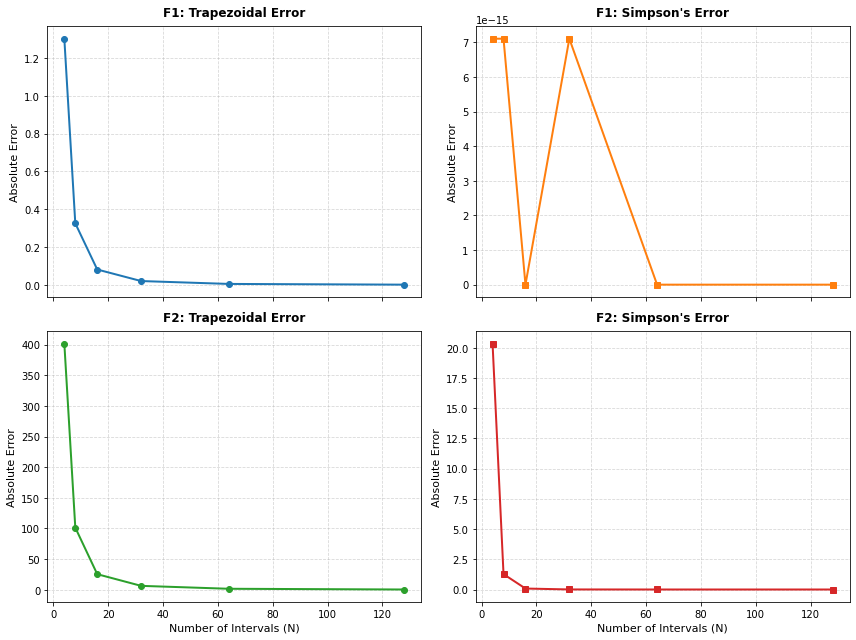

In [140]:
import matplotlib.pyplot as plt

# Set a clean, professional aesthetic style
fig, axs = plt.subplots(2, 2, figsize=(12, 9), sharex=True)

# Flatten the axes array for easy indexing
(ax1, ax2), (ax3, ax4) = axs

# --- Function 1 Plotting ---
ax1.plot(interval_counts, f1_trap_errors, color='#1f77b4', marker='o', linewidth=2, label='Trapezoidal')
ax1.set_title("F1: Trapezoidal Error", fontsize=12, fontweight='bold', pad=10)

ax2.plot(interval_counts, f1_sim_errors, color='#ff7f0e', marker='s', linewidth=2, label="Simpson's")
ax2.set_title("F1: Simpson's Error", fontsize=12, fontweight='bold', pad=10)

# --- Function 2 Plotting ---
ax3.plot(interval_counts, f2_trap_errors, color='#2ca02c', marker='o', linewidth=2, label='Trapezoidal')
ax3.set_title("F2: Trapezoidal Error", fontsize=12, fontweight='bold', pad=10)
ax3.set_xlabel("Number of Intervals (N)", fontsize=11)

ax4.plot(interval_counts, f2_sim_errors, color='#d62728', marker='s', linewidth=2, label="Simpson's")
ax4.set_title("F2: Simpson's Error", fontsize=12, fontweight='bold', pad=10)
ax4.set_xlabel("Number of Intervals (N)", fontsize=11)

# --- Universal Enhancements for All Subplots ---
for ax in axs.flat:
#     ax.set_yscale('log')                       # Crucial for seeing small error drops
#     ax.set_xscale('log')                       # Optional: makes the interval steps look linear
    ax.set_ylabel("Absolute Error", fontsize=11)
    ax.grid(True, which="both", linestyle="--", alpha=0.5)
    ax.tick_params(labelsize=10)
    
# Adjust spacing so titles and labels do not overlap
plt.tight_layout()
plt.show()


# Conclusion & Computation Accuracy
The above plots show that the accuracy increases as the number of integration points increase.
We can use the Algorithmic Complexity (Big O Notation). Both the rules share same complexity O(N) where N is the number of intervals.

| Metric | Trapezoidal Rule | Simpson's Rule |
| :--- | :---: | ---: |
| Mathematical Operations | Slightly Faster:<br>Multiplies internal nodes by \(2\). | Slightly Slower:<br> Alternates weights between \(4\) and \(2\).
| 
Error Decay Rate | $$\mathcal{O}(h^2) or \mathcal{O}(1/N^2)$$ (Quadratic)|$$\mathcal{O}(h^4) or \mathcal{O}(1/N^4) $$(Quartic)|
| Accuracy Efficiency | Needs huge \(N\) (high computing cost) for deep precision. | Needs tiny \(N\) (low computing cost) for deep precision.
| 


 


